# Distracted Driver Detection (UE24CS352A – ML Mini-Project, Problem #24)

Classifies driver images (State Farm dataset: 10 classes = safe driving + 9 distractions) with five models:
**Linear SVM, Softmax, Two-layer NN** (NumPy, from scratch) and **Gaussian Naive Bayes, Decision Tree** (scikit-learn).
Pipeline: image 640x480x3 → resize 64x64x3 → flatten (12,288) → scale to [0,1], subtract train-mean image → classifier.
Based on the CS229 report *Machine Learning Techniques for Distracted Driver Detection* (Feng & Yue, 2019).

**Run All** does everything: downloads the data, runs both evaluation protocols (random split and driver-wise split),
prints the results, generates `writeup.pdf` and `slides.pptx`, and runs the live demo.
Works on Google Colab (CPU is enough), Kaggle Notebooks, or a local machine.

## 1. Setup and configuration

In [1]:
import os
# Colab only: if you authenticate with a Kaggle API token string, uncomment and paste it here.
# NEVER commit a real token to GitHub.
# os.environ["KAGGLE_API_TOKEN"] = "PASTE_YOUR_TOKEN_HERE"

In [2]:
import os, sys, glob, json, time, itertools, subprocess, shutil, zipfile
import numpy as np
import cv2
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules

# ---------------- configuration ----------------
DATA_DIR        = "data/state-farm"    # filled in automatically by ensure_data() below
RUNS            = [("random", False, "results_random"),    # (name, split_by_driver, output folder)
                   ("driver", True,  "results_driver")]    # driver-wise: whole drivers held out for validation
MODELS_TO_RUN   = ["nb", "tree", "svm", "softmax", "nn"]
TUNE            = True       # grid-search lr/reg for svm, softmax, nn (scored on an inner split of TRAIN)
ITERS           = 2000
IMG_SIZE        = 64
LIMIT_PER_CLASS = None       # e.g. 200 for a quick smoke test (about 2 min)
SEED            = 0

In [3]:
# ---------------- get the data ----------------
COMP = "state-farm-distracted-driver-detection"

def _find_parent(root):
    hits = glob.glob(os.path.join(root, "**", "train", "c0"), recursive=True)
    return os.path.dirname(os.path.dirname(hits[0])) if hits else None

def _kaggle_login():
    """Colab: either set os.environ["KAGGLE_API_TOKEN"] beforehand, or upload kaggle.json when asked."""
    home = os.path.expanduser("~/.kaggle")
    if any(os.path.exists(os.path.join(home, f)) for f in ("kaggle.json", "access_token")) \
            or os.environ.get("KAGGLE_USERNAME") or os.environ.get("KAGGLE_API_TOKEN"):
        return
    if IN_COLAB:
        from google.colab import files
        print("Upload your kaggle.json now ...")
        up = files.upload()
        os.makedirs(home, exist_ok=True)
        shutil.move(next(iter(up)), os.path.join(home, "kaggle.json"))
        os.chmod(os.path.join(home, "kaggle.json"), 0o600)
    else:
        raise RuntimeError("No Kaggle credentials. Put kaggle.json in ~/.kaggle or download the data manually (see README).")

def _kaggle(*args):
    r = subprocess.run(["kaggle", *args], capture_output=True, text=True)
    print((r.stdout + r.stderr).strip()[-400:])
    return r.returncode == 0

def _extract_from_zip(zpath, raw):
    """Pull out only what we need: train images, the csv, and any nested zip (imgs.zip / csv.zip)."""
    with zipfile.ZipFile(zpath) as zf:
        names = zf.namelist()
        for m in names:
            if os.path.basename(m) in ("driver_imgs_list.csv", "driver_imgs_list.csv.zip", "imgs.zip"):
                zf.extract(m, raw)
        train = [m for m in names if m.startswith("train/") or "/train/" in m]
        if train:
            print(f"  extracting {len(train)} training images from {os.path.basename(zpath)} ...")
            zf.extractall(raw, train)

def ensure_data(data_dir=DATA_DIR):
    """Returns a folder containing train/c0..c9 and driver_imgs_list.csv, downloading from Kaggle if needed."""
    for d in (data_dir, f"/kaggle/input/{COMP}"):
        p = _find_parent(d)
        if p and os.path.exists(os.path.join(p, "driver_imgs_list.csv")):
            return p
    raw = "data/raw"; os.makedirs(raw, exist_ok=True)
    if _find_parent(raw) is None:
        if not glob.glob(os.path.join(raw, "*.zip")):
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=True)
            _kaggle_login()
            print("Downloading (about 4 GB, a few minutes). You must have accepted the competition rules on Kaggle.")
            _kaggle("competitions", "files", COMP)                    # shows the real file names
            _kaggle("competitions", "download", "-c", COMP, "-f", "driver_imgs_list.csv", "-p", raw)
            _kaggle("competitions", "download", "-c", COMP, "-f", "imgs.zip", "-p", raw)
            if not glob.glob(os.path.join(raw, "imgs.zip")):
                print("Single-file download failed, trying the full competition download (a bit slower) ...")
                if not _kaggle("competitions", "download", "-c", COMP, "-p", raw):
                    raise RuntimeError("Kaggle download failed. Did you accept the rules at "
                                       f"https://www.kaggle.com/c/{COMP}/rules ? (see message above)")
        done = set()
        for _ in range(3):                                            # outer zip -> nested imgs.zip / csv.zip
            for z in sorted(glob.glob(os.path.join(raw, "**", "*.zip"), recursive=True)):
                if z not in done:
                    done.add(z); _extract_from_zip(z, raw)
    parent = _find_parent(raw)
    if parent is None:
        raise RuntimeError("Could not find train/c0 after extraction - check data/raw.")
    csvs = glob.glob(os.path.join(raw, "**", "driver_imgs_list.csv"), recursive=True)
    dst = os.path.join(parent, "driver_imgs_list.csv")
    if csvs and not os.path.exists(dst):
        shutil.copy(csvs[0], dst)
    return parent

DATA_DIR = ensure_data()
n_img = sum(len(os.listdir(os.path.join(DATA_DIR, "train", f"c{c}"))) for c in range(10))
print(f"Data OK: {DATA_DIR}  ({n_img} training images; expected 22424)")


imgs/test/img_10001.jpg        39447  2019-12-15 22:37:08.739000  
imgs/test/img_100010.jpg       45723  2019-12-15 22:37:08.713000  
imgs/test/img_100011.jpg       39139  2019-12-15 22:37:08.706000  
imgs/test/img_100012.jpg       46822  2019-12-15 22:37:08.736000  
imgs/test/img_100013.jpg       35174  2019-12-15 22:37:08.711000  
imgs/test/img_100014.jpg       42614  2019-12-15 22:37:08.703000


  0%|          | 0.00/480k [00:00<?, ?B/s]
100%|██████████| 480k/480k [00:01<00:00, 418kB/s]
100%|██████████| 480k/480k [00:01<00:00, 418kB/s]
404 Client Error: Not Found for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFile
Single-file download failed, trying the full competition download (a bit slower) ...
4.00G [04:05<00:01, 18.0MB/s]
100%|█████████▉| 3.98G/4.00G [04:05<00:01, 18.5MB/s]
100%|█████████▉| 3.99G/4.00G [04:05<00:00, 18.9MB/s]
100%|█████████▉| 3.99G/4.00G [04:06<00:00, 18.2MB/s]
100%|█████████▉| 3.99G/4.00G [04:06<00:00, 18.7MB/s]
100%|███████

## 2. Data loading and preprocessing

In [4]:
CLASS_NAMES = [
    "Safe driving", "Texting - right", "Talking on phone - right",
    "Texting - left", "Talking on phone - left", "Operating the radio",
    "Drinking", "Reaching behind", "Hair and makeup", "Talking to passenger",
]


def _list_images(data_dir):
    """Return (paths, labels, subjects). Uses driver_imgs_list.csv when present."""
    train_dir = os.path.join(data_dir, "train")
    csv_path = os.path.join(data_dir, "driver_imgs_list.csv")
    if os.path.exists(csv_path):
        import pandas as pd
        df = pd.read_csv(csv_path)
        paths = [os.path.join(train_dir, c, f) for c, f in zip(df["classname"], df["img"])]
        labels = df["classname"].str[1:].astype(int).values
        return paths, labels, df["subject"].values
    paths, labels = [], []
    for c in range(10):
        for p in sorted(glob.glob(os.path.join(train_dir, f"c{c}", "*.jpg"))):
            paths.append(p)
            labels.append(c)
    return paths, np.array(labels), None


def load_dataset(data_dir, size=64, cache="data_cache.npz", limit_per_class=None):
    """Returns X (N, size*size*3) uint8, y (N,), subjects (N,) or None."""
    if cache and os.path.exists(cache):
        d = np.load(cache, allow_pickle=True)
        print(f"Loaded cached arrays from {cache}")
        subj = d["subjects"] if d["subjects"].ndim > 0 else None
        return d["X"], d["y"], subj

    paths, labels, subjects = _list_images(data_dir)
    if not paths:
        raise FileNotFoundError(f"No images found under {data_dir}/train/c0..c9")
    if limit_per_class:  # handy for quick tests
        r = np.random.RandomState(0)   # random (not first-N) subset, so a quick test still covers many drivers
        keep = np.sort(np.concatenate([r.permutation(np.where(labels == c)[0])[:limit_per_class] for c in range(10)]))
        paths = [paths[i] for i in keep]
        labels = labels[keep]
        subjects = subjects[keep] if subjects is not None else None

    X = np.empty((len(paths), size * size * 3), dtype=np.uint8)
    for i, p in enumerate(paths):
        img = cv2.imread(p)                       # BGR, 480x640x3
        img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
        X[i] = img[:, :, ::-1].reshape(-1)        # to RGB, flatten
        if (i + 1) % 2000 == 0:
            print(f"  preprocessed {i + 1}/{len(paths)}")
    if cache:
        np.savez_compressed(cache, X=X, y=labels,
                            subjects=subjects if subjects is not None else np.array(None))
    return X, labels, subjects


def split_indices(n, subjects=None, val_frac=0.2, by_driver=False, seed=0):
    """Return (train_idx, val_idx). by_driver=True keeps every driver entirely in train or val
    (avoids near-duplicate frames of the same person leaking into validation)."""
    rng = np.random.RandomState(seed)
    if by_driver:
        if subjects is None:
            raise ValueError("by_driver split needs driver_imgs_list.csv")
        drivers = np.unique(subjects)
        rng.shuffle(drivers)
        val_drivers = set(drivers[: max(1, int(len(drivers) * val_frac))])
        val_mask = np.array([s in val_drivers for s in subjects])
        return np.where(~val_mask)[0], np.where(val_mask)[0]
    idx = rng.permutation(n)
    n_val = int(n * val_frac)
    return idx[n_val:], idx[:n_val]


def train_val_split(X, y, subjects=None, val_frac=0.2, by_driver=False, seed=0):
    """80/20 split of the arrays (see split_indices)."""
    tr, va = split_indices(len(y), subjects, val_frac, by_driver, seed)
    return X[tr], y[tr], X[va], y[va]


def normalize(X_train, X_val, mean=None):
    """Scale to [0,1] and subtract the training mean image.
    Returns (X_train, X_val, mean). Pass `mean` to reuse a saved mean image (inference)."""
    Xt = X_train.astype(np.float32) / 255.0
    Xv = X_val.astype(np.float32) / 255.0
    if mean is None:
        mean = Xt.mean(axis=0, keepdims=True)
    return Xt - mean, Xv - mean, mean


def preprocess_image(path, size=64):
    """Single image file -> flat uint8 vector (same pipeline as training)."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img[:, :, ::-1].reshape(1, -1)

In [5]:
def acc(pred, y):
    return float(np.mean(pred == y))

def confusion(y, pred, k=10):
    cm = np.zeros((k, k), dtype=int)
    np.add.at(cm, (y, pred), 1)
    return cm

## 3. Models
Linear SVM and softmax (loss + gradient, trained with mini-batch SGD), a two-layer ReLU network, and the scikit-learn baselines.

In [6]:
# ---------------------------------------------------------------- losses
def svm_loss(W, b, X, y, reg):
    """Multi-class hinge loss (eq. 1) + L2 regularisation. Returns loss, dW, db."""
    N = X.shape[0]
    scores = X @ W + b
    correct = scores[np.arange(N), y][:, None]
    margins = np.maximum(0, scores - correct + 1.0)
    margins[np.arange(N), y] = 0
    loss = margins.sum() / N + reg * np.sum(W * W)
    mask = (margins > 0).astype(X.dtype)
    mask[np.arange(N), y] = -mask.sum(axis=1)
    dW = X.T @ mask / N + 2 * reg * W
    db = mask.sum(axis=0) / N
    return loss, dW, db


def softmax_loss(W, b, X, y, reg):
    """Cross-entropy loss (eq. 4) + L2 regularisation. Returns loss, dW, db."""
    N = X.shape[0]
    scores = X @ W + b
    scores -= scores.max(axis=1, keepdims=True)
    probs = np.exp(scores)
    probs /= probs.sum(axis=1, keepdims=True)
    loss = -np.log(probs[np.arange(N), y] + 1e-12).mean() + reg * np.sum(W * W)
    dscores = probs
    dscores[np.arange(N), y] -= 1
    dscores /= N
    return loss, X.T @ dscores + 2 * reg * W, dscores.sum(axis=0)


# ---------------------------------------------------------------- linear models
class LinearClassifier:
    """kind='svm' or 'softmax'; trained with mini-batch SGD (eq. 2)."""

    def __init__(self, kind="svm", seed=0):
        self.kind, self.seed = kind, seed
        self.loss_fn = svm_loss if kind == "svm" else softmax_loss
        self.W = self.b = None

    def fit(self, X, y, lr=1e-3, reg=1e-3, iters=2000, batch=256, num_classes=10, verbose=True):
        rng = np.random.RandomState(self.seed)   # fixed seed -> reproducible init (paper: init sensitivity)
        N, D = X.shape
        self.W = (0.001 * rng.randn(D, num_classes)).astype(X.dtype)
        self.b = np.zeros(num_classes, dtype=X.dtype)
        history = []
        for it in range(iters):
            idx = rng.choice(N, min(batch, N), replace=False)
            loss, dW, db = self.loss_fn(self.W, self.b, X[idx], y[idx], reg)
            self.W -= lr * dW
            self.b -= lr * db
            history.append(loss)
            if verbose and it % 200 == 0:
                print(f"    [{self.kind}] iter {it:4d}/{iters}  loss {loss:.4f}")
        return history

    def scores(self, X):
        return X @ self.W + self.b

    def predict(self, X):
        return np.argmax(self.scores(X), axis=1)   # eq. 3

    def save(self, path):
        np.savez(path, kind=self.kind, W=self.W, b=self.b)

    @classmethod
    def load(cls, path):
        d = np.load(path, allow_pickle=False)
        clf = cls(str(d["kind"]))
        clf.W, clf.b = d["W"], d["b"]
        return clf


# ---------------------------------------------------------------- two-layer net
class TwoLayerNet:
    """Input -> Affine -> ReLU (100 units) -> Affine -> Softmax."""

    def __init__(self, input_dim, hidden=100, num_classes=10, seed=0):
        rng = np.random.RandomState(seed)
        self.p = {
            "W1": (rng.randn(input_dim, hidden) * np.sqrt(2.0 / input_dim)).astype(np.float32),  # He init
            "b1": np.zeros(hidden, dtype=np.float32),
            "W2": (rng.randn(hidden, num_classes) * np.sqrt(2.0 / hidden)).astype(np.float32),
            "b2": np.zeros(num_classes, dtype=np.float32),
        }
        self.seed = seed

    def _loss_grads(self, X, y, reg):
        p, N = self.p, X.shape[0]
        h_pre = X @ p["W1"] + p["b1"]
        h = np.maximum(0, h_pre)
        scores = h @ p["W2"] + p["b2"]
        scores -= scores.max(axis=1, keepdims=True)
        probs = np.exp(scores)
        probs /= probs.sum(axis=1, keepdims=True)
        loss = -np.log(probs[np.arange(N), y] + 1e-12).mean()
        loss += 0.5 * reg * (np.sum(p["W1"] ** 2) + np.sum(p["W2"] ** 2))
        d = probs
        d[np.arange(N), y] -= 1
        d /= N
        g = {"W2": h.T @ d + reg * p["W2"], "b2": d.sum(0)}
        dh = d @ p["W2"].T
        dh[h_pre <= 0] = 0
        g["W1"] = X.T @ dh + reg * p["W1"]
        g["b1"] = dh.sum(0)
        return loss, g

    def fit(self, X, y, X_val=None, y_val=None, lr=1e-2, lr_decay=0.9, reg=1e-3,
            iters=2000, batch=200, verbose=True):
        rng = np.random.RandomState(self.seed)
        N = X.shape[0]
        per_epoch = max(N // batch, 1)
        history = []
        for it in range(iters):
            idx = rng.choice(N, batch, replace=False)
            loss, g = self._loss_grads(X[idx], y[idx], reg)
            for k in self.p:
                self.p[k] -= lr * g[k]
            history.append(loss)
            if (it + 1) % per_epoch == 0:
                lr *= lr_decay
            if verbose and it % 200 == 0:
                msg = f"    [two-layer-net] iter {it:4d}/{iters}  loss {loss:.4f}"
                if X_val is not None:
                    msg += f"  val acc {np.mean(self.predict(X_val) == y_val):.4f}"
                print(msg)
        return history

    def scores(self, X):
        h = np.maximum(0, X @ self.p["W1"] + self.p["b1"])
        return h @ self.p["W2"] + self.p["b2"]

    def predict(self, X):
        return np.argmax(self.scores(X), axis=1)

    def save(self, path):
        np.savez(path, kind="nn", **self.p)

    @classmethod
    def load(cls, path):
        d = np.load(path, allow_pickle=False)
        net = cls(d["W1"].shape[0], hidden=d["W1"].shape[1], num_classes=d["W2"].shape[1])
        net.p = {k: d[k] for k in ("W1", "b1", "W2", "b2")}
        return net


def load_model(path):
    """Load a saved from-scratch model (svm / softmax / nn)."""
    kind = str(np.load(path, allow_pickle=False)["kind"])
    return TwoLayerNet.load(path) if kind == "nn" else LinearClassifier.load(path)


# ---------------------------------------------------------------- sklearn baselines
def make_naive_bayes():
    from sklearn.naive_bayes import GaussianNB
    return GaussianNB()


def make_decision_tree(seed=0):
    from sklearn.tree import DecisionTreeClassifier
    return DecisionTreeClassifier(random_state=seed)

## 4. Gradient check (verifies the from-scratch maths)
Analytic gradients must match numerical gradients (errors should be ~1e-6 or smaller).

In [7]:
def _num_grad(f, W, h=1e-5):
    g = np.zeros_like(W)
    for i in np.ndindex(*W.shape):
        old = W[i]; W[i] = old + h; a = f(); W[i] = old - h; b = f(); W[i] = old
        g[i] = (a - b) / (2 * h)
    return g

rng = np.random.RandomState(0)
Xg, yg = rng.randn(20, 30), rng.randint(0, 10, 20)
for name, fn in (("svm", svm_loss), ("softmax", softmax_loss)):
    W, b = rng.randn(30, 10) * 0.1, rng.randn(10) * 0.1
    _, dW, db = fn(W, b, Xg, yg, 0.01)
    print(f"{name:8s} max |dW error| = {np.abs(dW - _num_grad(lambda: fn(W, b, Xg, yg, 0.01)[0], W)).max():.2e}")
net = TwoLayerNet(30, hidden=8)
net.p = {k: v.astype(np.float64) for k, v in net.p.items()}
_, g = net._loss_grads(Xg.copy(), yg, 0.01)
for k in net.p:
    print(f"nn {k:3s}   max |error|    = {np.abs(g[k] - _num_grad(lambda: net._loss_grads(Xg.copy(), yg, 0.01)[0], net.p[k])).max():.2e}")

svm      max |dW error| = 2.11e-10
softmax  max |dW error| = 7.40e-11
nn W1    max |error|    = 5.65e-11
nn b1    max |error|    = 2.77e-11
nn W2    max |error|    = 5.64e-11
nn b2    max |error|    = 3.68e-11


## 5. Experiment runner (split, tune, train, evaluate)

In [8]:
GRIDS = {"svm":     ([3e-5, 1e-4, 3e-4, 1e-3], [1e-4, 1e-3, 1e-2]),
         "softmax": ([3e-5, 1e-4, 3e-4, 1e-3], [1e-4, 1e-3, 1e-2]),
         "nn":      ([3e-3, 1e-2, 3e-2],       [1e-4, 1e-3, 1e-2])}

def tune(kind, iters, Xtt, ytt, Xi, yi):
    """Grid search lr x reg, scored on the inner split (never on the final validation set)."""
    best_acc, best_hp = -1, None
    for lr, reg in itertools.product(*GRIDS[kind]):
        clf = TwoLayerNet(Xtt.shape[1]) if kind == "nn" else LinearClassifier(kind)
        clf.fit(Xtt, ytt, lr=lr, reg=reg, iters=iters, verbose=False)
        a = acc(clf.predict(Xi), yi)
        print(f"    tune {kind}: lr={lr:g} reg={reg:g} -> inner-val {a:.4f}")
        if a > best_acc:
            best_acc, best_hp = a, dict(lr=lr, reg=reg)
    print(f"    best {kind}: {best_hp}")
    return best_hp


def run_experiment(tag, by_driver, out_dir, X, y, subj):
    os.makedirs(out_dir, exist_ok=True)
    tr, va = split_indices(len(y), subj, by_driver=by_driver, seed=SEED)
    Xt, yt, Xv, yv = X[tr], y[tr], X[va], y[va]
    Xt, Xv, mean_img = normalize(Xt, Xv)
    np.savez(os.path.join(out_dir, "preprocess.npz"), mean=mean_img, size=IMG_SIZE)
    print(f"split = {'by driver' if by_driver else 'random'} | train {Xt.shape} | val {Xv.shape}")
    if subj is not None:
        print(f"drivers: {len(set(subj[tr]))} in train, {len(set(subj[va]))} in val, {len(set(subj[tr]) & set(subj[va]))} in both")

    if TUNE:   # inner split of the TRAIN set, used only to choose hyper-parameters
        sub_tr = subj[tr] if subj is not None else None
        itr, iva = split_indices(len(yt), sub_tr, by_driver=by_driver and sub_tr is not None, seed=SEED + 1)
        Xtt, ytt, Xi, yi = Xt[itr], yt[itr], Xt[iva], yt[iva]

    results, preds, models, histories = {}, {}, {}, {}
    for name in MODELS_TO_RUN:
        print(f"\n=== [{tag}] {name} ===")
        t0 = time.time()
        hp = {}
        if name in ("nb", "tree"):
            if name == "tree": print("    fitting decision tree on 12,288 features (can take 5-15 min) ...")
            clf = make_naive_bayes() if name == "nb" else make_decision_tree(SEED)
            clf.fit(Xt, yt)
        elif name in ("svm", "softmax"):
            hp = tune(name, max(ITERS // 4, 200), Xtt, ytt, Xi, yi) if TUNE else dict(lr=1e-3, reg=1e-3)
            clf = LinearClassifier(name, seed=SEED)
            histories[name] = clf.fit(Xt, yt, iters=ITERS, **hp)
        else:
            hp = tune("nn", max(ITERS // 4, 200), Xtt, ytt, Xi, yi) if TUNE else {}
            clf = TwoLayerNet(Xt.shape[1], seed=SEED)
            histories[name] = clf.fit(Xt, yt, Xv, yv, iters=ITERS, **hp)
        if name in ("svm", "softmax", "nn"):
            clf.save(os.path.join(out_dir, f"model_{name}.npz"))
        models[name] = clf
        p_tr, p_va = clf.predict(Xt), clf.predict(Xv)
        preds[name] = p_va
        results[name] = dict(train_acc=acc(p_tr, yt), val_acc=acc(p_va, yv), seconds=round(time.time() - t0, 1))
        if hp: results[name]["hyperparams"] = hp
        print(f"  train acc {results[name]['train_acc']:.4f} | val acc {results[name]['val_acc']:.4f} | {results[name]['seconds']}s")

    # ---- summary, per-class accuracy, confusion matrix, loss curves
    print(f"\n[{tag}] {'model':<10}{'train acc':>12}{'val acc':>12}")
    for n in MODELS_TO_RUN:
        print(f"[{tag}] {n:<10}{100 * results[n]['train_acc']:>12.2f}{100 * results[n]['val_acc']:>12.2f}")
    best = max(MODELS_TO_RUN, key=lambda n: results[n]["val_acc"])
    cm = confusion(yv, preds[best])
    per_class = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
    print(f"\nBest model: {best}. Per-class accuracy:")
    for c, a in enumerate(per_class):
        print(f"  c{c} {CLASS_NAMES[c]:<26}{100 * a:6.2f}%")
    results["best_model"] = best
    results["per_class_acc"] = {CLASS_NAMES[c]: float(a) for c, a in enumerate(per_class)}
    results["config"] = dict(split="by-driver" if by_driver else "random", n_train=int(len(yt)), n_val=int(len(yv)),
                             iters=ITERS, size=IMG_SIZE, seed=SEED, tuned=TUNE)
    results["confusion_matrix"] = cm.tolist()
    json.dump(results, open(os.path.join(out_dir, "results.json"), "w"), indent=2)

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticklabels([f"c{i}" for i in range(10)]); ax.set_yticklabels([f"c{i}" for i in range(10)])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix ({best}, {tag} split)")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
    fig.tight_layout(); fig.savefig(os.path.join(out_dir, "confusion_matrix.png"), dpi=120); plt.show()

    k = max(len(histories), 1)
    fig, axs = plt.subplots(1, k, figsize=(5 * k, 3.5))
    for ax, (n, h) in zip(np.atleast_1d(axs), histories.items()):
        ax.plot(h); ax.set_title(f"{n} training loss ({tag})"); ax.set_xlabel("iteration"); ax.set_ylabel("loss")
    fig.tight_layout(); fig.savefig(os.path.join(out_dir, "loss_curves.png"), dpi=120); plt.show()
    return results

## 6. Run both evaluation protocols
This is the long step (the decision tree dominates). Output of every model is printed as it finishes.

  preprocessed 2000/22424
  preprocessed 4000/22424
  preprocessed 6000/22424
  preprocessed 8000/22424
  preprocessed 10000/22424
  preprocessed 12000/22424
  preprocessed 14000/22424
  preprocessed 16000/22424
  preprocessed 18000/22424
  preprocessed 20000/22424
  preprocessed 22000/22424
images: (22424, 12288) | drivers: 26

  PROTOCOL: random  (split_by_driver=False)
split = random | train (17940, 12288) | val (4484, 12288)
drivers: 26 in train, 26 in val, 26 in both

=== [random] nb ===
  train acc 0.5547 | val acc 0.5522 | 30.9s

=== [random] tree ===
    fitting decision tree on 12,288 features (can take 5-15 min) ...
  train acc 1.0000 | val acc 0.8912 | 261.7s

=== [random] svm ===
    tune svm: lr=3e-05 reg=0.0001 -> inner-val 0.3403
    tune svm: lr=3e-05 reg=0.001 -> inner-val 0.3403
    tune svm: lr=3e-05 reg=0.01 -> inner-val 0.3403
    tune svm: lr=0.0001 reg=0.0001 -> inner-val 0.4908
    tune svm: lr=0.0001 reg=0.001 -> inner-val 0.4908
    tune svm: lr=0.0001 reg=0.0

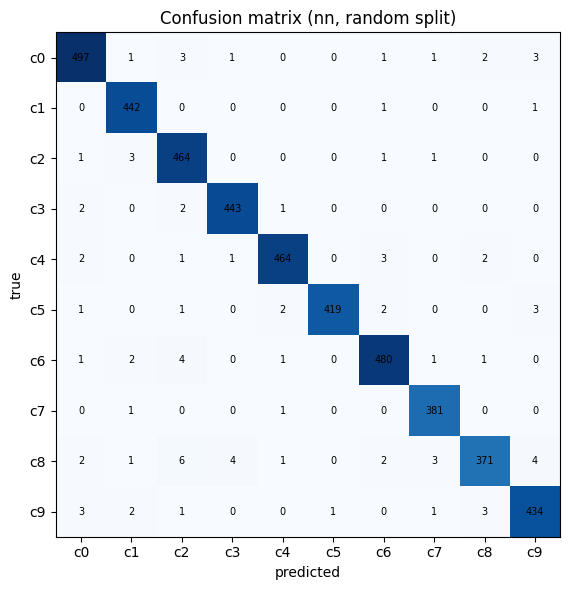

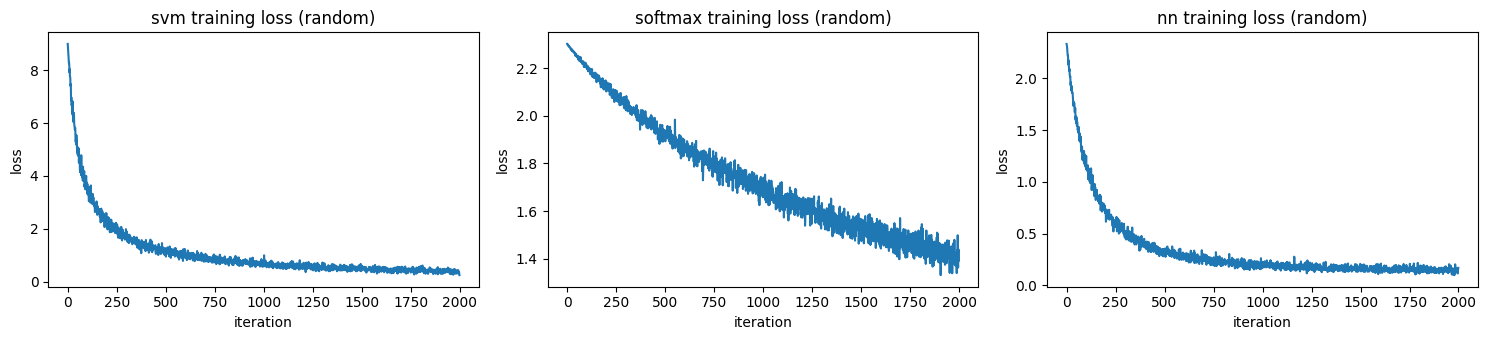


  PROTOCOL: driver  (split_by_driver=True)
split = by driver | train (17747, 12288) | val (4677, 12288)
drivers: 21 in train, 5 in val, 0 in both

=== [driver] nb ===
  train acc 0.6112 | val acc 0.3261 | 25.6s

=== [driver] tree ===
    fitting decision tree on 12,288 features (can take 5-15 min) ...
  train acc 1.0000 | val acc 0.2966 | 230.6s

=== [driver] svm ===
    tune svm: lr=3e-05 reg=0.0001 -> inner-val 0.1595
    tune svm: lr=3e-05 reg=0.001 -> inner-val 0.1595
    tune svm: lr=3e-05 reg=0.01 -> inner-val 0.1595
    tune svm: lr=0.0001 reg=0.0001 -> inner-val 0.2439
    tune svm: lr=0.0001 reg=0.001 -> inner-val 0.2439
    tune svm: lr=0.0001 reg=0.01 -> inner-val 0.2435
    tune svm: lr=0.0003 reg=0.0001 -> inner-val 0.2727
    tune svm: lr=0.0003 reg=0.001 -> inner-val 0.2731
    tune svm: lr=0.0003 reg=0.01 -> inner-val 0.2731
    tune svm: lr=0.001 reg=0.0001 -> inner-val 0.2499
    tune svm: lr=0.001 reg=0.001 -> inner-val 0.2506
    tune svm: lr=0.001 reg=0.01 -> inne

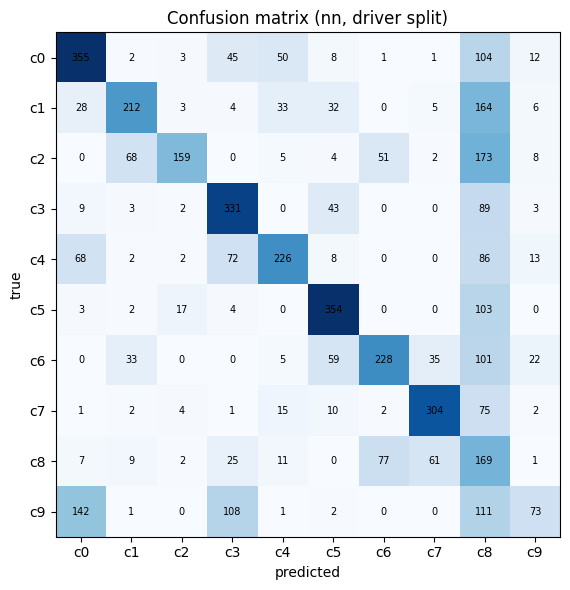

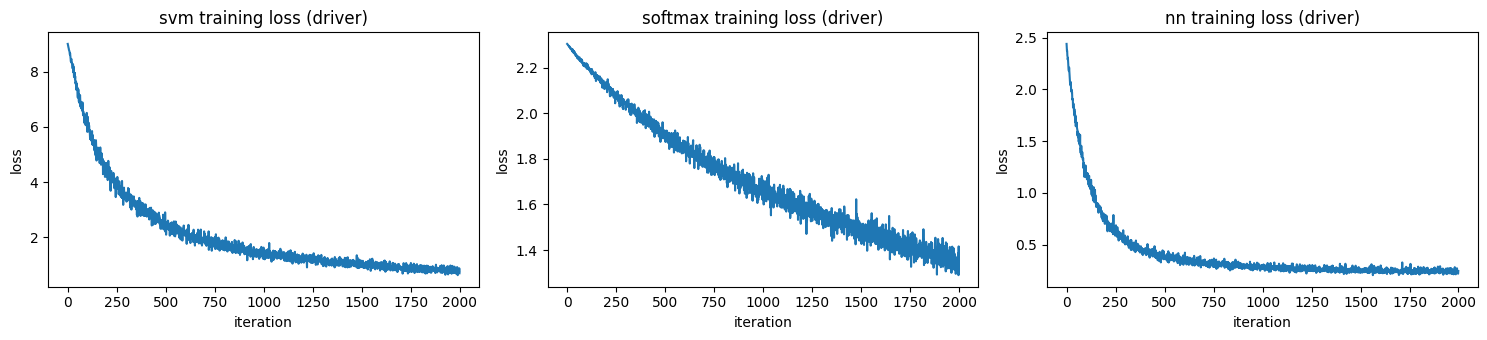

In [9]:
X, y, subj = load_dataset(DATA_DIR, IMG_SIZE, cache=f"cache_{IMG_SIZE}_{LIMIT_PER_CLASS}.npz", limit_per_class=LIMIT_PER_CLASS)
print("images:", X.shape, "| drivers:", None if subj is None else len(set(subj)))
ALL = {}
for tag, by_driver, out_dir in RUNS:
    print("\n" + "=" * 70 + f"\n  PROTOCOL: {tag}  (split_by_driver={by_driver})\n" + "=" * 70)
    ALL[tag] = run_experiment(tag, by_driver, out_dir, X, y, subj)

## 7. Side-by-side comparison

In [10]:
print(f"{'model':<10}" + "".join(f"{t + ' train':>16}{t + ' val':>14}" for t, _, _ in RUNS))
for n in MODELS_TO_RUN:
    print(f"{n:<10}" + "".join(f"{100 * ALL[t][n]['train_acc']:>16.2f}{100 * ALL[t][n]['val_acc']:>14.2f}" for t, _, _ in RUNS))
for t, _, _ in RUNS:
    print(f"best on {t}: {ALL[t]['best_model']}")

model         random train    random val    driver train    driver val
nb                   55.47         55.22           61.12         32.61
tree                100.00         89.12          100.00         29.66
svm                  96.16         95.34           93.63         45.39
softmax              71.69         71.39           75.97         41.93
nn                   98.57         98.02           99.10         51.55
best on random: nn
best on driver: nn


## 8. Live demo: classify a driver image
Loads the saved model, so it also works after a restart. Set `IMAGE_PATH` to any driver photo (leave `None` to pick a random one from the dataset).

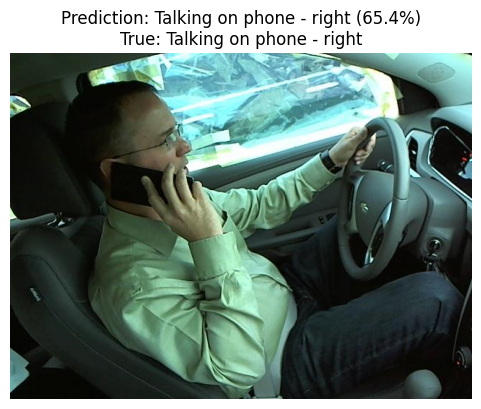

c2 Talking on phone - right   65.4%
c6 Drinking                   20.0%
c8 Hair and makeup             9.3%


In [11]:
DEMO_DIR   = "results_driver"     # which run's saved model to use
DEMO_MODEL = "nn"                  # nn, svm or softmax
IMAGE_PATH = None                  # e.g. "data/state-farm/train/c3/img_1.jpg"

model = load_model(os.path.join(DEMO_DIR, f"model_{DEMO_MODEL}.npz"))
pp = np.load(os.path.join(DEMO_DIR, "preprocess.npz"))
mean_img, size = pp["mean"], int(pp["size"])
true_label = None
if IMAGE_PATH is None:
    c = int(np.random.randint(10))
    IMAGE_PATH = np.random.choice(glob.glob(os.path.join(DATA_DIR, "train", f"c{c}", "*.jpg")))
    true_label = CLASS_NAMES[c]

def softmax_probs(s):
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

x = preprocess_image(IMAGE_PATH, size).astype(np.float32) / 255.0 - mean_img
probs = softmax_probs(model.scores(x))[0]
order = np.argsort(-probs)[:3]
plt.figure(figsize=(6, 4.5)); plt.imshow(cv2.imread(IMAGE_PATH)[:, :, ::-1]); plt.axis("off")
plt.title(f"Prediction: {CLASS_NAMES[order[0]]} ({100 * probs[order[0]]:.1f}%)" + (f"\nTrue: {true_label}" if true_label else ""))
plt.show()
for k in order:
    print(f"c{k} {CLASS_NAMES[k]:<26}{100 * probs[k]:5.1f}%")

## 9. Generate `writeup.pdf` and `slides.pptx` from the results
Fill in your details, then run the two cells below. The text and numbers come straight from `results_*/results.json`.

In [12]:
# ===== EDIT THESE =====
NAMES    = ["Arya Devang", "Ananthakrishna"]
SRNS     = ["PES1UG24AM054", "PES1UG24AM036"]
REPO_URL = "https://github.com/Arya-677/ML_miniProject_sem5"
# ======================
try:
    import reportlab, pptx
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "reportlab", "python-pptx"], check=True)

In [13]:
# --- report generator (write-up PDF + slides) ---
"""Builds writeup.pdf (max 2 pages) and slides.pptx from results_random/results.json and results_driver/results.json."""
import io, json, os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

CLASS_NAMES = ["Safe driving", "Texting - right", "Talking on phone - right", "Texting - left",
               "Talking on phone - left", "Operating the radio", "Drinking", "Reaching behind",
               "Hair and makeup", "Talking to passenger"]
MODEL_LABEL = {"nb": "Naive Bayes", "tree": "Decision Tree", "svm": "Linear SVM",
               "softmax": "Softmax", "nn": "Two-layer NN"}
MODEL_ORDER = ["nb", "tree", "svm", "softmax", "nn"]
PAPER = {"nn": 92.24, "softmax": 82.31, "svm": 71.39, "tree": 84.73, "nb": 54.99}   # CS229 report, random split


def pct(p, d=1):
    return f"{100 * p:.{d}f}%"


def load(random_dir, driver_dir):
    R = {}
    for tag, d in (("random", random_dir), ("driver", driver_dir)):
        p = os.path.join(d, "results.json")
        R[tag] = json.load(open(p)) if os.path.exists(p) else None
    if R["random"] is None and R["driver"] is None:
        raise FileNotFoundError("No results.json found - run the experiments first.")
    return R


def models_in(R):
    ms = [m for m in MODEL_ORDER if any(R[t] and m in R[t] for t in R)]
    return ms


def get(R, tag, m, key):
    r = R.get(tag)
    return r[m][key] if r and m in r else None


def insights(R):
    """Plain-English findings generated from the numbers. Returns list of strings."""
    out = []
    ms = models_in(R)
    for tag, nm in (("random", "random split"), ("driver", "driver-wise split")):
        r = R[tag]
        if not r:
            continue
        rank = sorted(ms, key=lambda m: -r[m]["val_acc"])
        s = ", ".join(f"{MODEL_LABEL[m]} {pct(r[m]['val_acc'])}" for m in rank)
        out.append(f"On the {nm}, validation accuracy ranks: {s}.")
    if R["random"] and R["driver"]:
        drops = {m: R["random"][m]["val_acc"] - R["driver"][m]["val_acc"] for m in ms}
        b = R["driver"]["best_model"]
        avg = 100 * np.mean(list(drops.values()))
        out.append(f"Holding out whole drivers changes the best model ({MODEL_LABEL[b]}) from "
                   f"{pct(R['random'][b]['val_acc'])} to {pct(R['driver'][b]['val_acc'])}; averaged over all models, validation accuracy "
                   + (f"falls by {avg:.1f} points." if avg >= 0 else f"rises by {-avg:.1f} points."))
        if avg > 5:
            out.append("A large drop is what we would expect if the random split is optimistic: frames of the same driver are "
                       "near-duplicates, so a model can partly memorise people instead of learning the activity.")
        elif avg > 1:
            out.append("The drop is moderate, so some of the random-split accuracy came from seeing the same drivers in training.")
        else:
            out.append("The drop is small, so leakage of drivers between train and validation affected these models only slightly.")
    ref = R["driver"] or R["random"]
    b = ref["best_model"]
    gap = 100 * (ref[b]["train_acc"] - ref[b]["val_acc"])
    out.append(f"The best model ({MODEL_LABEL[b]}) fits the training set at {pct(ref[b]['train_acc'])} against "
               f"{pct(ref[b]['val_acc'])} on validation, a gap of {gap:.1f} points"
               + (" - clear overfitting, so stronger regularisation, augmentation or a CNN would help." if gap > 10
                  else " - little overfitting."))
    pc = ref["per_class_acc"]
    srt = sorted(pc.items(), key=lambda kv: kv[1])
    out.append(f"Hardest classes for {MODEL_LABEL[b]}: {srt[0][0]} ({pct(srt[0][1])}) and {srt[1][0]} ({pct(srt[1][1])}); "
               f"easiest: {srt[-1][0]} ({pct(srt[-1][1])}).")
    cm = np.array(ref["confusion_matrix"])
    off = cm.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    if off.max() > 0:
        out.append(f"Most frequent confusion: '{CLASS_NAMES[i]}' predicted as '{CLASS_NAMES[j]}' ({off[i, j]} validation images).")
    if R["random"]:
        rn = R["random"]
        out.append(f"Our random-split numbers can be compared with the reference report (two-layer net 92.2%, softmax 82.3%, "
                   f"SVM 71.4%, decision tree 84.7%, Naive Bayes 55.0%): ours are {pct(rn['nn']['val_acc'])}, "
                   f"{pct(rn['softmax']['val_acc'])}, {pct(rn['svm']['val_acc'])}, {pct(rn['tree']['val_acc'])} and "
                   f"{pct(rn['nb']['val_acc'])}." if all(m in rn for m in ("nn", "softmax", "svm", "tree", "nb")) else
                   "Our random-split numbers can be compared with the reference report (two-layer net 92.2%).")
    return out


def _cfg(R):
    r = R["driver"] or R["random"]
    return r["config"]


def results_rows(R):
    ms = models_in(R)
    rows = [["Model", "Random: train", "Random: val", "Driver-wise: train", "Driver-wise: val"]]
    for m in ms:
        row = [MODEL_LABEL[m]]
        for tag in ("random", "driver"):
            for k in ("train_acc", "val_acc"):
                v = get(R, tag, m, k)
                row.append("-" if v is None else f"{100 * v:.2f}")
        rows.append(row)
    return rows


def confusion_png(R, path):
    ref = R["driver"] or R["random"]
    cm = np.array(ref["confusion_matrix"])
    b = ref["best_model"]
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ax.imshow(cm / np.maximum(cm.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticklabels([f"c{i}" for i in range(10)], fontsize=8); ax.set_yticklabels([f"c{i}" for i in range(10)], fontsize=8)
    ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
    tag = "driver-wise" if R["driver"] else "random"
    ax.set_title(f"Confusion matrix - {MODEL_LABEL[b]} ({tag} validation)", fontsize=9)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                    color="white" if cm[i, j] / max(cm[i].sum(), 1) > 0.5 else "black")
    fig.tight_layout(); fig.savefig(path, dpi=170); plt.close(fig)


# ---------------------------------------------------------------------------------------------- PDF
def build_pdf(R, names, srns, repo_url, out_pdf, workdir="."):
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import ParagraphStyle
    from reportlab.lib import colors
    from reportlab.lib.units import cm as CM
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, KeepTogether

    cfg = _cfg(R)
    team = " | ".join(f"{n} ({s})" for n, s in zip(names, srns))
    png = os.path.join(workdir, "_confusion_for_pdf.png"); confusion_png(R, png)
    ins = insights(R)
    ms = models_in(R)
    n_tr, n_va = cfg["n_train"], cfg["n_val"]

    for fs in (9.6, 9.2, 8.8, 8.4, 8.0, 7.6):
        base = ParagraphStyle("b", fontName="Helvetica", fontSize=fs, leading=fs * 1.25, spaceAfter=2.5)
        h1 = ParagraphStyle("h1", parent=base, fontName="Helvetica-Bold", fontSize=fs + 1.6, leading=(fs + 1.6) * 1.2,
                            textColor=colors.HexColor("#1F3A5F"), spaceBefore=5, spaceAfter=2)
        title = ParagraphStyle("t", parent=base, fontName="Helvetica-Bold", fontSize=15, leading=18, textColor=colors.HexColor("#1F3A5F"))
        small = ParagraphStyle("s", parent=base, fontSize=fs - 0.6, leading=(fs - 0.6) * 1.25, textColor=colors.HexColor("#444444"))
        bl = ParagraphStyle("bl", parent=base, leftIndent=10, bulletIndent=0)

        st = []
        st.append(Paragraph("Distracted Driver Detection from Dashboard Images", title))
        st.append(Paragraph(f"UE24CS352A Machine Learning - Mini-Project (Problem #24) | {team}", small))
        st.append(Paragraph(f"Code: {repo_url} (private; shared with faculty/TAs)", small))

        st.append(Paragraph("1. Problem statement", h1))
        st.append(Paragraph(
            "Given one in-cabin camera image of a driver, predict what the driver is doing: safe driving or one of nine "
            "distractions (texting or talking on the phone with the left or right hand, operating the radio, drinking, reaching "
            "behind, hair/makeup, talking to a passenger). This is a 10-class image classification problem. We re-implement the "
            "CS229 report <i>Machine Learning Techniques for Distracted Driver Detection</i> (Feng &amp; Yue, 2019): five classifiers "
            "on raw pixels. We also ask whether their accuracy carries over to drivers never seen in training.", base))

        st.append(Paragraph("2. Dataset", h1))
        st.append(Paragraph(
            "State Farm Distracted Driver Detection (Kaggle): 22,424 labelled 640x480 RGB images in 10 classes (c0 safe driving, "
            "c1-c9 distractions), about 2,000-2,500 per class, from 26 drivers; <font face='Courier'>driver_imgs_list.csv</font> gives the "
            "driver of every image. The images are frames of short videos, so frames of one driver are almost identical. The "
            "official test images are unlabelled, so we hold out 20% of the labelled images for validation "
            f"(this run: {n_tr:,} training / {n_va:,} validation images).", base))

        st.append(Paragraph("3. Approach", h1))
        for t in (
            "<b>Pre-processing:</b> resize to 64x64x3 (OpenCV, area interpolation), flatten to a 12,288-vector, scale to [0,1], "
            "subtract the training mean image (computed on training data only).",
            "<b>Models:</b> linear SVM (multi-class hinge loss + L2), softmax regression (cross-entropy + L2) and a two-layer network "
            "(100 ReLU units, softmax output, He initialisation, learning-rate decay) - all from scratch in NumPy; Gaussian Naive "
            "Bayes and a Decision Tree from scikit-learn with default settings.",
            "<b>Two protocols:</b> (i) random 80/20 split, as in the reference report; (ii) driver-wise 80/20 split in which no driver "
            "appears in both sets, which measures generalisation to new people.",
            "<b>Tuning:</b> learning rate and regularisation of the SVM, softmax and network are chosen by grid search on an inner "
            "split of the training data, so the validation set is used only for the final numbers.",
        ):
            st.append(Paragraph(t, bl, bulletText="\u2022"))

        st.append(Paragraph("4. Implementation overview", h1))
        st.append(Paragraph(
            "Everything is in one Python notebook (<font face='Courier'>distracted_driver_detection.ipynb</font>): data loading and caching, "
            "vectorised losses and back-propagation, mini-batch SGD with a fixed random seed (SVM/softmax are sensitive to initialisation), "
            "a numerical gradient check of all analytic gradients, hyper-parameter search, evaluation (accuracy, per-class accuracy, "
            "confusion matrix, loss curves), saved models and a live-demo cell that classifies any image. "
            "Results of each run are written to <font face='Courier'>results_*/results.json</font>.", base))

        st.append(Paragraph("5. Results and conclusions", h1))
        data = results_rows(R)
        tbl = Table(data, colWidths=[3.4 * CM, 3.0 * CM, 3.0 * CM, 3.6 * CM, 3.6 * CM], hAlign="LEFT")
        best_rows = []
        for tag, ci in (("random", 2), ("driver", 4)):
            if R[tag]:
                bm = R[tag]["best_model"]
                best_rows.append((ci, 1 + ms.index(bm)))
        style = [("FONT", (0, 0), (-1, -1), "Helvetica", fs - 0.4), ("FONT", (0, 0), (-1, 0), "Helvetica-Bold", fs - 0.4),
                 ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#E6ECF4")), ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#999999")),
                 ("ALIGN", (1, 0), (-1, -1), "CENTER"), ("TOPPADDING", (0, 0), (-1, -1), 1.5), ("BOTTOMPADDING", (0, 0), (-1, -1), 1.5)]
        for c, r in best_rows:
            style.append(("FONT", (c, r), (c, r), "Helvetica-Bold", fs - 0.4))
            style.append(("BACKGROUND", (c, r), (c, r), colors.HexColor("#D9EAD3")))
        tbl.setStyle(TableStyle(style))
        st.append(Paragraph("Accuracy (%) on the training and validation sets; best validation result of each protocol in bold/green.", small))
        st.append(tbl)
        st.append(Spacer(1, 3))
        txt = [Paragraph(t, bl, bulletText="\u2022") for t in ins]
        img = Image(png, width=6.2 * CM, height=6.2 * CM * 4.6 / 5.2)
        side = Table([[txt, img]], colWidths=[10.9 * CM, 6.4 * CM], hAlign="LEFT")
        side.setStyle(TableStyle([("VALIGN", (0, 0), (-1, -1), "TOP"), ("LEFTPADDING", (0, 0), (-1, -1), 0),
                                  ("RIGHTPADDING", (0, 0), (-1, -1), 4)]))
        st.append(side)
        st.append(Paragraph(
            "<b>Limitations and next steps.</b> 64x64 raw pixels lose detail (phone versus hand) and fully-connected models ignore spatial "
            "structure; results use a single seed and a single split. Next: a CNN or transfer learning, data augmentation, driver-grouped "
            "k-fold cross-validation, and semi-supervised use of the unlabelled test images.", base))

        buf = io.BytesIO()
        doc = SimpleDocTemplate(buf, pagesize=A4, leftMargin=1.6 * CM, rightMargin=1.6 * CM, topMargin=1.3 * CM, bottomMargin=1.2 * CM,
                                title="Distracted Driver Detection - write-up")
        doc.build(st)
        if doc.page <= 2:
            open(out_pdf, "wb").write(buf.getvalue())
            return fs, doc.page
    raise RuntimeError("Could not fit the write-up on 2 pages")


# ---------------------------------------------------------------------------------------------- PPTX
def build_pptx(R, names, srns, repo_url, out_pptx, workdir="."):
    from pptx import Presentation
    from pptx.util import Inches, Pt
    from pptx.dml.color import RGBColor
    from pptx.enum.shapes import MSO_SHAPE
    from pptx.enum.text import PP_ALIGN, MSO_ANCHOR
    from pptx.chart.data import CategoryChartData
    from pptx.enum.chart import XL_CHART_TYPE, XL_LEGEND_POSITION

    NAVY, TEAL, GREY, LIGHT, WHITE = (RGBColor(0x1F, 0x3A, 0x5F), RGBColor(0x1B, 0x8A, 0x8F), RGBColor(0x55, 0x5B, 0x66),
                                      RGBColor(0xEE, 0xF3, 0xF8), RGBColor(0xFF, 0xFF, 0xFF))
    ORANGE = RGBColor(0xD9, 0x7B, 0x29)
    prs = Presentation(); prs.slide_width, prs.slide_height = Inches(13.333), Inches(7.5)
    blank = prs.slide_layouts[6]
    team = " | ".join(f"{n} ({s})" for n, s in zip(names, srns))
    cfg = _cfg(R); ms = models_in(R); ins = insights(R)

    def text(sl, x, y, w, h, s, size=16, bold=False, color=GREY, align=PP_ALIGN.LEFT, anchor=MSO_ANCHOR.TOP, font="Calibri"):
        tb = sl.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h)); tf = tb.text_frame; tf.word_wrap = True
        tf.vertical_anchor = anchor
        lines = s if isinstance(s, list) else [s]
        for i, ln in enumerate(lines):
            p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
            p.alignment = align; r = p.add_run(); r.text = ln
            r.font.size, r.font.bold, r.font.color.rgb, r.font.name = Pt(size), bold, color, font
        return tb

    def bullets(sl, x, y, w, h, items, size=17, gap=8):
        tb = sl.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h)); tf = tb.text_frame; tf.word_wrap = True
        for i, it in enumerate(items):
            p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
            p.space_after = Pt(gap)
            r = p.add_run(); r.text = "\u25B8  " + it; r.font.size = Pt(size); r.font.color.rgb = GREY; r.font.name = "Calibri"

    def box(sl, x, y, w, h, fill=LIGHT, line=None, shape=MSO_SHAPE.ROUNDED_RECTANGLE):
        s = sl.shapes.add_shape(shape, Inches(x), Inches(y), Inches(w), Inches(h))
        s.fill.solid(); s.fill.fore_color.rgb = fill
        if line: s.line.color.rgb = line
        else: s.line.fill.background()
        s.shadow.inherit = False
        return s

    def slide(title):
        sl = prs.slides.add_slide(blank)
        bar = box(sl, 0, 0, 13.333, 1.05, fill=NAVY, shape=MSO_SHAPE.RECTANGLE)
        text(sl, 0.6, 0.12, 12, 0.85, title, size=30, bold=True, color=WHITE, anchor=MSO_ANCHOR.MIDDLE)
        text(sl, 0.6, 7.05, 12.1, 0.35, f"UE24CS352A  |  ML Mini-Project #24  |  {team}", size=10, color=GREY)
        return sl

    def card(sl, x, y, w, h, head, body, tag=None, head_color=NAVY, size=14):
        box(sl, x, y, w, h)
        text(sl, x + 0.15, y + 0.1, w - 0.3, 0.5, head, size=18, bold=True, color=head_color)
        text(sl, x + 0.15, y + 0.65, w - 0.3, h - 1.0, body, size=size)
        if tag: text(sl, x + 0.15, y + h - 0.42, w - 0.3, 0.35, tag, size=10, bold=True, color=TEAL)

    # 1 title
    sl = prs.slides.add_slide(blank)
    box(sl, 0, 0, 13.333, 7.5, fill=NAVY, shape=MSO_SHAPE.RECTANGLE)
    box(sl, 0.8, 3.55, 1.6, 0.07, fill=TEAL, shape=MSO_SHAPE.RECTANGLE)
    text(sl, 0.8, 1.6, 11.5, 1.8, "Distracted Driver Detection", size=48, bold=True, color=WHITE)
    text(sl, 0.8, 2.6, 11.5, 0.9, "Classifying driver activity from dashboard images: classical ML vs a small neural network", size=22, color=RGBColor(0xCF, 0xDB, 0xEA))
    text(sl, 0.8, 3.9, 11.5, 1.6, ["UE24CS352A  |  Machine Learning  |  Mini-Project  |  Problem #24", team, repo_url], size=16, color=WHITE)

    # 2 problem
    sl = slide("The problem")
    bullets(sl, 0.6, 1.4, 6.6, 4.8, [
        "Task: given ONE in-cabin image, predict the driver's activity (10 classes).",
        "Why it matters: distracted driving contributes to severe crashes, and different activities carry different risk.",
        "Our question: how well do simple models on raw pixels work, and does the accuracy hold for drivers the model has never seen?",
        "Basis: re-implementation and extension of the CS229 report by Feng & Yue (2019)."], size=19, gap=14)
    box(sl, 7.6, 1.4, 5.1, 5.3)
    text(sl, 7.8, 1.5, 4.7, 0.5, "The 10 classes", size=18, bold=True, color=NAVY)
    text(sl, 7.8, 2.1, 4.7, 4.5, [f"c{i}   {n}" for i, n in enumerate(CLASS_NAMES)], size=17)

    # 3 dataset
    sl = slide("Dataset: State Farm Distracted Driver Detection (Kaggle)")
    for k, (big, small) in enumerate([("22,424", "labelled images"), ("10", "classes (1 safe + 9 distractions)"),
                                      ("26", "different drivers"), ("640x480", "RGB in-cabin camera")]):
        x = 0.6 + k * 3.1
        box(sl, x, 1.4, 2.9, 1.7)
        text(sl, x, 1.5, 2.9, 0.9, big, size=34, bold=True, color=TEAL, align=PP_ALIGN.CENTER)
        text(sl, x + 0.1, 2.4, 2.7, 0.7, small, size=14, align=PP_ALIGN.CENTER)
    bullets(sl, 0.6, 3.5, 12.1, 3.3, [
        "Only the training folder is labelled (the official test images are not), so we hold out 20% of it for validation.",
        "driver_imgs_list.csv gives the driver ID of every image.",
        "The catch: images are frames from short videos, so frames of one driver look almost identical. A random split can put the "
        "same driver in train AND validation, which may inflate accuracy.",
        f"This run: {cfg['n_train']:,} training and {cfg['n_val']:,} validation images."], size=18, gap=12)

    # 4 pipeline
    sl = slide("Pre-processing pipeline")
    steps = [("Image", "640x480x3"), ("Resize", "64x64x3\n(OpenCV, area)"), ("Flatten", "12,288-vector"),
             ("Normalise", "divide by 255,\nminus train mean image"), ("Classifier", "5 models")]
    for k, (h, b) in enumerate(steps):
        x = 0.6 + k * 2.5
        box(sl, x, 1.7, 2.1, 1.7, fill=TEAL if k in (1, 3) else LIGHT)
        c = WHITE if k in (1, 3) else NAVY
        text(sl, x, 1.8, 2.1, 0.5, h, size=19, bold=True, color=c, align=PP_ALIGN.CENTER)
        text(sl, x + 0.05, 2.4, 2.0, 0.9, b.split("\n"), size=13, color=c, align=PP_ALIGN.CENTER)
        if k < 4: text(sl, x + 2.08, 2.2, 0.45, 0.6, "\u279C", size=24, bold=True, color=NAVY, align=PP_ALIGN.CENTER)
    bullets(sl, 0.6, 4.0, 12.1, 2.8, [
        "Why 64x64: 640x480x3 is about 921k values per image, too large for from-scratch NumPy models; 12,288 is manageable.",
        "The mean image comes from the TRAIN set only, so validation data never influences preprocessing.",
        "Preprocessed images are cached once as .npz so repeated runs are fast."], size=18, gap=12)

    # 5 models
    sl = slide("Five models")
    mdl = [("Linear SVM", "Multi-class hinge loss + L2.\nScores = W x + b,\nmini-batch SGD.", "FROM SCRATCH (NumPy)"),
           ("Softmax", "Cross-entropy + L2.\nSame linear scores,\nprobabilistic output.", "FROM SCRATCH (NumPy)"),
           ("Two-layer NN", "12,288 -> 100 ReLU -> 10\nsoftmax. He init,\nLR decay each epoch.", "FROM SCRATCH (NumPy)"),
           ("Naive Bayes", "Gaussian per pixel,\nassumes pixels are\nindependent.", "scikit-learn"),
           ("Decision Tree", "Axis-aligned splits on\npixel values.\nDefault settings.", "scikit-learn")]
    for k, (h, b, t) in enumerate(mdl):
        card(sl, 0.45 + k * 2.5, 1.5, 2.35, 3.6, h, b.split("\n"), tag=t, size=15)
    bullets(sl, 0.6, 5.5, 12.1, 1.4, ["All analytic gradients are checked against numerical gradients (see notebook, section 4).",
                                       "SVM, softmax and the network tune learning rate and regularisation by grid search."], size=17, gap=8)

    # 6 protocol
    sl = slide("Evaluation protocol")
    card(sl, 0.6, 1.4, 5.9, 2.2, "1  Random 80/20 split", ["Comparable to the reference report.", "Frames of the same driver can be on both sides."],
         tag="MAY BE OPTIMISTIC", head_color=ORANGE, size=16)
    card(sl, 6.8, 1.4, 5.9, 2.2, "2  Driver-wise 80/20 split", ["Whole drivers are held out for validation.", "Tests generalisation to people never seen in training."],
         tag="STRICTER TEST", head_color=TEAL, size=16)
    bullets(sl, 0.6, 4.0, 12.1, 3.0, [
        "Hyper-parameters: grid search over learning rate x regularisation for SVM, softmax and the network.",
        "No peeking: tuning is scored on an inner split of the TRAIN set; validation is used once for the final number.",
        "Metrics: train/validation accuracy, per-class accuracy, confusion matrix of the best model.",
        "Reproducible: fixed random seed (these models are sensitive to weight initialisation)."], size=18, gap=11)

    # 7 results
    sl = slide("Results: validation accuracy")
    rows = results_rows(R)
    tb = sl.shapes.add_table(len(rows), 5, Inches(0.5), Inches(1.4), Inches(7.0), Inches(0.5 * len(rows))).table
    for r, row in enumerate(rows):
        for c, v in enumerate(row):
            cell = tb.cell(r, c); cell.text = v
            p = cell.text_frame.paragraphs[0]; p.alignment = PP_ALIGN.LEFT if c == 0 else PP_ALIGN.CENTER
            p.runs[0].font.size = Pt(12 if r == 0 else 14); p.runs[0].font.bold = (r == 0)
            p.runs[0].font.color.rgb = WHITE if r == 0 else GREY
            cell.fill.solid(); cell.fill.fore_color.rgb = NAVY if r == 0 else (LIGHT if r % 2 else WHITE)
    tb.columns[0].width = Inches(1.9)
    for c in range(1, 5): tb.columns[c].width = Inches(1.275)
    cd = CategoryChartData(); cd.categories = [MODEL_LABEL[m] for m in ms]
    for tag, nm in (("random", "Random split"), ("driver", "Driver-wise split")):
        if R[tag]: cd.add_series(nm, [round(100 * R[tag][m]["val_acc"], 2) for m in ms])
    ch = sl.shapes.add_chart(XL_CHART_TYPE.COLUMN_CLUSTERED, Inches(7.7), Inches(1.3), Inches(5.3), Inches(4.2), cd).chart
    ch.has_legend = True; ch.legend.position = XL_LEGEND_POSITION.BOTTOM; ch.legend.include_in_layout = False
    ch.legend.font.size = Pt(11)
    ch.value_axis.maximum_scale = 100; ch.value_axis.minimum_scale = 0; ch.value_axis.tick_labels.font.size = Pt(11)
    ch.category_axis.tick_labels.font.size = Pt(10); ch.value_axis.has_major_gridlines = False
    pl = ch.plots[0]; pl.has_data_labels = True; pl.data_labels.font.size = Pt(9); pl.data_labels.number_format = "0.0"
    pl.data_labels.number_format_is_linked = False
    cols = [ORANGE, TEAL]
    for s, col in zip(pl.series, cols): s.format.fill.solid(); s.format.fill.fore_color.rgb = col
    text(sl, 0.5, 1.4 + 0.5 * len(rows) + 0.2, 7.0, 1.2,
         ["Accuracy in %. Reference report (random split): NN 92.24, softmax 82.31, SVM 71.39, tree 84.73, Naive Bayes 54.99."], size=12)
    b = (R["driver"] or R["random"])["best_model"]
    text(sl, 0.5, 5.7, 12.3, 1.2, f"Best model: {MODEL_LABEL[b]}.", size=20, bold=True, color=NAVY)

    # 8 confusion matrix
    sl = slide(f"Best model in detail: {MODEL_LABEL[b]}")
    png = os.path.join(workdir, "_confusion_for_pptx.png"); confusion_png(R, png)
    sl.shapes.add_picture(png, Inches(0.5), Inches(1.3), height=Inches(5.5))
    ref = R["driver"] or R["random"]
    srt = sorted(ref["per_class_acc"].items(), key=lambda kv: kv[1])
    bullets(sl, 6.7, 1.4, 6.1, 5.3, ["Per-class validation accuracy, hardest first:"] +
            [f"{n}: {pct(a)}" for n, a in srt[:4]] + ["...and easiest:"] + [f"{n}: {pct(a)}" for n, a in srt[-2:]], size=17, gap=9)

    # 9 analysis
    sl = slide("What the results tell us")
    bullets(sl, 0.6, 1.3, 12.1, 5.6, ins, size=17, gap=9)

    # 10 implementation
    sl = slide("Implementation")
    text(sl, 0.6, 1.4, 5.6, 4.6, ["repo/", "  distracted_driver_detection.ipynb", "  README.md", "  requirements.txt",
                                   "  writeup.pdf", "  slides.pptx", "  results_random/",
                                   "  results_driver/"], size=15, font="Consolas")
    bullets(sl, 6.4, 1.4, 6.4, 5.4, [
        "From scratch: vectorised losses and back-propagation in NumPy.",
        "Verified: numerical gradient check, error below 1e-6.",
        "Leak-free: driver-wise split, train-only mean image, tuning on an inner split.",
        "Reproducible: fixed seed; everything runs top to bottom in one notebook.",
        "Cached: preprocessed images stored once as .npz.",
        "Saved models are reused by the live-demo cell."], size=17, gap=10)

    # 11 demo
    sl = slide("Live demonstration")
    for k, (h, b2) in enumerate([("1  Open the notebook", "Final section loads the saved two-layer net and the mean image."),
                                 ("2  Pick an image", "Set IMAGE_PATH to any driver photo, e.g. one from data/state-farm/train/."),
                                 ("3  Run the cell", "Shows the image, the predicted activity and top-3 probabilities."),
                                 ("4  Show the outputs", "results_driver/results.json, confusion_matrix.png, loss_curves.png.")]):
        x = 0.6 + (k % 2) * 6.2; y = 1.5 + (k // 2) * 2.7
        card(sl, x, y, 5.9, 2.4, h, b2, size=18)

    # 12 conclusions
    sl = slide("Conclusions and future work")
    d = R["driver"]; r_ = R["random"]
    concl = ["Re-implemented SVM, softmax and a two-layer net from scratch; gradients verified numerically.",
             "Compared them with Naive Bayes and a decision tree under two evaluation protocols."]
    if d: concl.append(f"Driver-wise best: {MODEL_LABEL[d['best_model']]} at {pct(d[d['best_model']]['val_acc'])} validation accuracy.")
    if r_: concl.append(f"Random-split best: {MODEL_LABEL[r_['best_model']]} at {pct(r_[r_['best_model']]['val_acc'])}.")
    card(sl, 0.6, 1.4, 6.0, 5.3, "Conclusions", concl, size=18)
    card(sl, 6.9, 1.4, 5.8, 5.3, "Limitations and next steps",
         ["64x64 raw pixels lose detail (phone vs hand); fully-connected models ignore spatial structure.", "Single seed and single split.",
          "Next: CNN or transfer learning, data augmentation, driver-grouped k-fold CV, semi-supervised use of the unlabelled test images."], size=18)
    prs.save(out_pptx)
    return len(prs.slides)


def build_all(names, srns, repo_url, random_dir="results_random", driver_dir="results_driver",
              out_pdf="writeup.pdf", out_pptx="slides.pptx"):
    R = load(random_dir, driver_dir)
    fs, pages = build_pdf(R, names, srns, repo_url, out_pdf)
    n = build_pptx(R, names, srns, repo_url, out_pptx)
    print(f"{out_pdf}: {pages} page(s), body font {fs}pt | {out_pptx}: {n} slides")
    for t in insights(R):
        print(" -", t)


build_all(NAMES, SRNS, REPO_URL, random_dir="results_random", driver_dir="results_driver")

writeup.pdf: 2 page(s), body font 9.6pt | slides.pptx: 12 slides
 - On the random split, validation accuracy ranks: Two-layer NN 98.0%, Linear SVM 95.3%, Decision Tree 89.1%, Softmax 71.4%, Naive Bayes 55.2%.
 - On the driver-wise split, validation accuracy ranks: Two-layer NN 51.6%, Linear SVM 45.4%, Softmax 41.9%, Naive Bayes 32.6%, Decision Tree 29.7%.
 - Holding out whole drivers changes the best model (Two-layer NN) from 98.0% to 51.6%; averaged over all models, validation accuracy falls by 41.6 points.
 - A large drop is what we would expect if the random split is optimistic: frames of the same driver are near-duplicates, so a model can partly memorise people instead of learning the activity.
 - The best model (Two-layer NN) fits the training set at 99.1% against 51.6% on validation, a gap of 47.6 points - clear overfitting, so stronger regularisation, augmentation or a CNN would help.
 - Hardest classes for Two-layer NN: Talking to passenger (16.7%) and Talking on phone - right 

## 10. Bundle everything for download (Colab)

In [14]:
bundle = "submission_bundle"
shutil.rmtree(bundle, ignore_errors=True); os.makedirs(bundle)
for f in ("writeup.pdf", "slides.pptx"):
    shutil.copy(f, bundle)
for _, _, d in RUNS:
    shutil.copytree(d, os.path.join(bundle, d), ignore=shutil.ignore_patterns("cache.npz"))
shutil.make_archive("submission_bundle", "zip", bundle)
print("created submission_bundle.zip:", os.listdir(bundle))
if IN_COLAB:
    from google.colab import files
    files.download("submission_bundle.zip")

created submission_bundle.zip: ['slides.pptx', 'results_driver', 'results_random', 'writeup.pdf']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>